# TP1 - Apprentissage supervisé avec Python

**Étudiant :** Maxim Khomenko

**Numéro du TP :** 1

**Date :** 14 Novembre 2026

**Version Python :** 3.13.5

**Bibliothèques utilisées :** numpy, pandas, scikit-learn, matplotlib

In [1]:
import sys
import numpy as np
np.set_printoptions(threshold=sys.maxsize) # Remplacement de np.nan pour compatibilité NumPy
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

   Seniority  Home  Time   Age  Marital  Records  Job  Expenses  Income  \
0        9.0   1.0  60.0  30.0      0.0      1.0  1.0      73.0   129.0   
1       17.0   1.0  60.0  58.0      1.0      1.0  0.0      48.0   131.0   
2       10.0   0.0  36.0  46.0      0.0      2.0  1.0      90.0   200.0   
3        0.0   1.0  60.0  24.0      1.0      1.0  0.0      63.0   182.0   
4        0.0   1.0  36.0  26.0      1.0      1.0  0.0      46.0   107.0   

   Assets  Debt  Amount   Price  Status  
0     0.0   0.0   800.0   846.0       1  
1     0.0   0.0  1000.0  1658.0       1  
2  3000.0   0.0  2000.0  2985.0       0  
3  2500.0   0.0   900.0  1325.0       1  
4     0.0   0.0   310.0   910.0       1  
Taille de l'échantillon (lignes, colonnes) : (4375, 14)
Dimensions de X : (4375, 13) | Dimensions de y : (4375,)
Exemples positifs (Status = 1) : 3159
Exemples négatifs (Status = 0) : 1216


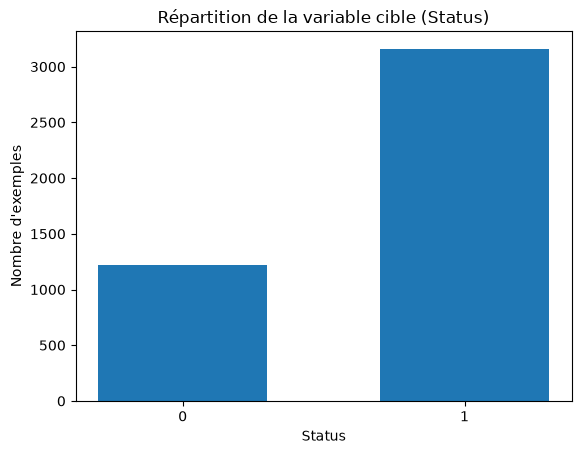

In [2]:
# 1. Importation du jeu de données
df = pd.read_csv("credit_scoring.csv", sep=";") # type: ignore
print(df.head())

# 2. Transformation en numpy array et séparation X / y
data = df.values
X = data[:, :-1]
y = data[:, -1]

# 3. Propriétés des données : taille et répartition des classes
print("Taille de l'échantillon (lignes, colonnes) :", data.shape)
print("Dimensions de X :", X.shape, "| Dimensions de y :", y.shape)
print("Exemples positifs (Status = 1) :", np.sum(y == 1))
print("Exemples négatifs (Status = 0) :", np.sum(y == 0))

plt.hist(y, bins=[-0.5, 0.5, 1.5], rwidth=0.6)
plt.xticks([0, 1])
plt.xlabel("Status")
plt.ylabel("Nombre d'exemples")
plt.title("Répartition de la variable cible (Status)")
plt.show()

# 4. Séparation apprentissage / test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [3]:
# Arbre CART
cart = DecisionTreeClassifier(random_state=0)
cart.fit(X_train, y_train)
y_pred_cart = cart.predict(X_test)
print("Accuracy CART (test) :", round(accuracy_score(y_test, y_pred_cart), 3))

# K-plus-proches-voisins (k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
print("Accuracy KNN k=5 (test) :", round(accuracy_score(y_test, y_pred_knn), 3))

Accuracy CART (test) : 0.736
Accuracy KNN k=5 (test) : 0.724


**Interprétation :**
Sur les données brutes, CART obtient une accuracy de 0.736 et KNN (k=5) de 0.724. Ces scores sont proches de la proportion de la classe majoritaire (Status = 1), soit 0.722 (3159/4375).

Les deux modèles font donc à peine mieux qu’un modèle naïf (+1,4 point pour CART, +0,2 point pour KNN). Comme les classes sont déséquilibrées (environ 72 % / 28 %), l’accuracy seule dit peu de choses sur la détection de la classe minoritaire.

In [4]:
# Normalisation avec StandardScaler
scaler_std = StandardScaler()
X_train_std = scaler_std.fit_transform(X_train)
X_test_std = scaler_std.transform(X_test)

cart.fit(X_train_std, y_train)
knn.fit(X_train_std, y_train)
print("Avec StandardScaler :")
print("Accuracy CART :", round(accuracy_score(y_test, cart.predict(X_test_std)), 3))
print("Accuracy KNN (k=5) :", round(accuracy_score(y_test, knn.predict(X_test_std)), 3))

# Test avec MinMaxScaler
scaler_mm = MinMaxScaler()
X_train_mm = scaler_mm.fit_transform(X_train)
X_test_mm = scaler_mm.transform(X_test)

cart.fit(X_train_mm, y_train)
knn.fit(X_train_mm, y_train)
print("\nAvec MinMaxScaler :")
print("Accuracy CART :", round(accuracy_score(y_test, cart.predict(X_test_mm)), 3))
print("Accuracy KNN (k=5) :", round(accuracy_score(y_test, knn.predict(X_test_mm)), 3))

Avec StandardScaler :
Accuracy CART : 0.736
Accuracy KNN (k=5) : 0.752

Avec MinMaxScaler :
Accuracy CART : 0.733
Accuracy KNN (k=5) : 0.744


**Interprétation :**
* CART : la normalisation ne change presque rien (0.736 sans, 0.736 avec StandardScaler, 0.733 avec MinMaxScaler). C’est attendu car un arbre compare chaque variable à un seuil indépendamment des autres, donc l’échelle n’influence pas les coupures (Partie 1, section 1.5.8 et Corrigé de l’exercice 1). L’écart de 0.003 avec MinMaxScaler est minime et pourrait venir des seuils choisis, pas de la normalisation elle-même.
* KNN : l’accuracy passe de 0.724 à 0.752 avec StandardScaler (+2,8 points) et à 0.744 avec MinMaxScaler (+2 points). KNN repose sur des distances, donc, sur les données brutes, les variables de grande amplitude (Assets, Price, Amount, Income) pesaient beaucoup plus que les autres. La normalisation supprime cette domination, ce qui semble expliquer le gain d’accuracy.

In [5]:
# Application de l'ACP sur les données normalisées
acp = PCA()
acp.fit(X_train_std)

# Récupération des valeurs propres et calcul de l'inertie cumulée pour chaque composante principale
valeurs_propres = acp.explained_variance_
inertie_cumulee = acp.explained_variance_ratio_.cumsum() * 100
composantes = [f"F{i+1}" for i in range(len(valeurs_propres))]

# Création et affichage du tableau
df_acp = pd.DataFrame({"Inertie cumulée (%)": inertie_cumulee.round(1), "Valeur propre": valeurs_propres.round(2)}, index=composantes)
print(df_acp)

# Règle de Kaiser : on garde k=5 composantes (valeurs propres > 1 et inertie > 50-70%)
acp_k = PCA(n_components=5)
X_train_acp = acp_k.fit_transform(X_train_std)
X_test_acp = acp_k.transform(X_test_std)

# Concaténation aux données normalisées de l'étape précédente
X_train_concat = np.hstack((X_train_std, X_train_acp))
X_test_concat = np.hstack((X_test_std, X_test_acp))
print("Nouvelles dimensions de X_train :", X_train_concat.shape)

# Ré-exécution des modèles
cart.fit(X_train_concat, y_train)
knn.fit(X_train_concat, y_train)
print("Accuracy CART (normalisé + ACP) :", round(accuracy_score(y_test, cart.predict(X_test_concat)), 3))
print("Accuracy KNN (normalisé + ACP) :", round(accuracy_score(y_test, knn.predict(X_test_concat)), 3))

     Inertie cumulée (%)  Valeur propre
F1                  19.2           2.49
F2                  33.9           1.92
F3                  44.2           1.34
F4                  53.2           1.16
F5                  61.8           1.12
F6                  69.4           0.99
F7                  76.6           0.94
F8                  82.2           0.73
F9                  87.5           0.68
F10                 92.2           0.62
F11                 95.5           0.42
F12                 98.5           0.40
F13                100.0           0.19
Nouvelles dimensions de X_train : (3062, 18)
Accuracy CART (normalisé + ACP) : 0.742
Accuracy KNN (normalisé + ACP) : 0.759


**Que se passe-t-il ?**

En concaténant les 5 premières composantes principales aux 13 variables normalisées, l'accuracy change peu par rapport à l'étape précédente (0.736 $\rightarrow$ 0.742 pour CART et 0.752 $\rightarrow$ 0.759 pour KNN). Ces écarts (+0,6 et +0,7 point) sont faibles et peuvent s’expliquer par le hasard du découpage, on ne peut pas en conclure que l’ACP améliore réellement les modèles.

* CART : un arbre ne produit que des frontières de décision parallèles aux axes. Les composantes principales étant des combinaisons linéaires des variables, elles permettent des coupures selon d’autres directions que les axes d’origine. Mais le gain de 0.006 est trop faible pour conclure.
* KNN : les composantes principales sont des combinaisons linéaires des variables déjà présentes. En les ajoutant, la même information compte plusieurs fois dans le calcul des distances, ce qui modifie légèrement les voisins sélectionnés. Ici aussi, le gain de 0,007 est trop faible pour faire une conclusion.